# SFT vs. Zeroshot output analysis (V-STaR, red-bbox visual grounding)

**Question being debugged.** After SFT on the OpenO3 dataset (keyframes with red
bounding boxes drawn) the V-STaR eval accuracy is essentially unchanged vs. the
zeroshot model run *with the same red bboxes drawn on V-STaR frames*:

| run | accuracy | avg score (0-3) |
|-----|----------|-----------------|
| zeroshot + red bbox | 0.5987 | 1.732 |
| SFT + red bbox      | 0.5958 | 1.744 |

Yet the SFT model's CoT clearly *attends to* the red boxes (uses the
`<obj>...</obj>at<t>..</t>s ... red bounding box` format). So why no gain?

This notebook does **not** re-run the model. It loads the two existing result
dumps and asks:

1. Are the two runs scoring the **same samples** right/wrong, or do they
   disagree a lot and just happen to net out to the same accuracy?
2. How much do the **generated answers actually differ** between the two runs?
   (If they barely differ, SFT is close to a no-op on the final answer.)
3. Does the SFT model really produce the grounded format more than zeroshot, and
   does using that format correlate with being correct?
4. For the disagreement cases (SFT-only-correct / ZS-only-correct), look at the
   actual text side by side, and render the annotated video to eyeball whether
   the red box is on the right object.

> The eval `score` is a 0-3 judge rating (Qwen2.5-72B). `verdict == True` means
> `score >= 2` (counted as correct in `accuracy`).


In [1]:
import os, sys, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

pd.set_option("display.max_colwidth", 200)

SFT_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_sft_vg_bbox/2026-05-29_22-33-49"
ZS_DIR  = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_zeroshot_vg_bbox/2026-05-24_20-00-11"

# Annotation masks + source videos (used only by the visualization section)
ANN_ROOT   = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/uniform_sample_cap_768/2026-05-19_19-14-38"
VIDEO_ROOT = "/projects/torresani-lab/ajay/datasets/V-STaR/videos"


## 1. Load both runs and merge on `qid`

The per-sample `score`/`verdict` live in `benchmark/evaluation_results.csv`; `domain` and `vid` live in `results.json`. We merge them and join the two runs side by side on `qid`.

In [2]:
def load_run(run_dir):
    """Return per-sample DataFrame for one run, merging eval CSV with results.json metadata."""
    csv_path = os.path.join(run_dir, "benchmark", "evaluation_results.csv")
    res_path = os.path.join(run_dir, "results.json")

    df = pd.read_csv(csv_path)
    df["score"] = df["score"].astype(int)
    df["correct"] = df["verdict"].astype(str).str.lower().eq("true")

    meta = pd.DataFrame(json.load(open(res_path)))[["qid", "vid", "domain", "num_frames_used"]]
    df = df.merge(meta, on="qid", how="left")
    return df

sft = load_run(SFT_DIR)
zs  = load_run(ZS_DIR)
print("SFT:", len(sft), "samples | ZS:", len(zs), "samples")
print("SFT acc:", sft.correct.mean().round(4), "| ZS acc:", zs.correct.mean().round(4))
sft.head(3)


SFT: 2083 samples | ZS: 2083 samples
SFT acc: 0.5372 | ZS acc: 0.5987


,qid,question,gt_answer,generated_answer,candidate_answer,score,verdict,correct,vid,domain,num_frames_used
0,7771650716_0,what walks in front of a man in white?,a dog with a rope walks in front of a man in white.,<think><obj>dog</obj>at<t>11</t>s is highlighted by a red bounding box and is walking in front of a man in white. The man in white is holding the dog on a leash.</think>\n<answer>the dog</answer>,the dog,1,False,False,7771650716,Animals,60
1,7771650716_1,what does the adult in white clothes hug?,an adult in white clothes hugs a brown dog.,"<think><obj>the adult</obj>at<t>10</t>s is wearing white clothes and is holding a small dog. The video shows the adult bending down and hugging the dog. The dog is on a leash, indicating that the ...",the adult in white clothes is hugging a small dog.,2,True,True,7771650716,Animals,60
2,6297019062_0,who is above the round and pink baby seat?,there is a baby above the round and pink baby seat.,"<think>\nThere are several babies in the video, each sitting in a baby seat. The image displays a baby in a pink and yellow costume sitting in a green baby seat, another baby in a pink outfit sitt...",The baby above the round and pink baby seat is wearing a yellow costume with a matching yellow hat.,3,True,True,6297019062,Nature,58


In [3]:
# Join the two runs on qid. Suffixes _sft / _zs.
keep = ["qid", "question", "gt_answer", "generated_answer", "score", "correct", "vid", "domain"]
m = sft[keep].merge(
    zs[["qid", "generated_answer", "score", "correct"]],
    on="qid", suffixes=("_sft", "_zs"),
)
assert len(m) == len(sft) == len(zs), "qid sets differ between runs!"
m["score_delta"] = m["score_sft"] - m["score_zs"]
print("merged:", len(m), "samples")
m[["qid", "domain", "score_sft", "score_zs", "score_delta", "correct_sft", "correct_zs"]].head()


merged: 2083 samples


,qid,domain,score_sft,score_zs,score_delta,correct_sft,correct_zs
0,7771650716_0,Animals,1,2,-1,False,True
1,7771650716_1,Animals,2,3,-1,True,True
2,6297019062_0,Nature,3,1,2,True,False
3,9293415110_0,Shows,1,1,0,False,False
4,9293415110_1,Shows,1,2,-1,False,True


In [4]:
# Pull the extra GT sub-questions from the V-STaR annotation file. results.json only carries
# the main `question`/`gt_answer`; the original GT also has a temporal_question (+ the GT
# `timestamps` window it refers to) and two spatial_question phrasings per qid. Join on qid.
VSTAR_GT = "/projects/torresani-lab/ajay/datasets/V-STaR/V_STaR_test_with_qid.json"

gt_extra = pd.DataFrame(json.load(open(VSTAR_GT)))[
    ["qid", "temporal_question", "timestamps", "spatial_question", "spatial_question_2"]
]
m = m.merge(gt_extra, on="qid", how="left")
print(f"matched GT sub-questions for {m.temporal_question.notna().sum()}/{len(m)} samples")
m[["qid", "temporal_question", "timestamps", "spatial_question"]].head(3)


matched GT sub-questions for 2083/2083 samples


,qid,temporal_question,timestamps,spatial_question
0,7771650716_0,When is the moment 'a dog with a rope walks in front of a man in white' occurring?,"[0.0, 13.0]",Where is the dog with a rope during the event of walking in front of a man in white between 0s and 13s?
1,7771650716_1,When does the adult in white clothes hug the brown dog?,"[31.2, 42.4]",Where is the brown dog being hugged by the adult in white clothes between 31.2s~42.4s?
2,6297019062_0,When is the moment 'there is a baby above the round and pink baby seat.'?,"[52.1, 58.3]",Where is the baby above the round and pink baby seat between 52.1s~58.3s?


## 2. Agreement analysis — are the same samples right/wrong?

If SFT genuinely changed behavior we'd expect the correctness sets to move. The 2x2 confusion of `correct_sft` vs `correct_zs` tells us directly: the off-diagonal cells are where the runs disagree.

In [5]:
conf = pd.crosstab(m["correct_sft"], m["correct_zs"], margins=True)
conf.index.name = "SFT correct"
conf.columns.name = "ZS correct"
print(conf)

both_correct = ((m.correct_sft) & (m.correct_zs)).sum()
both_wrong   = ((~m.correct_sft) & (~m.correct_zs)).sum()
sft_only     = ((m.correct_sft) & (~m.correct_zs)).sum()
zs_only      = ((~m.correct_sft) & (m.correct_zs)).sum()
n = len(m)
print(f"\nboth correct : {both_correct:4d} ({both_correct/n:.1%})")
print(f"both wrong   : {both_wrong:4d} ({both_wrong/n:.1%})")
print(f"SFT only     : {sft_only:4d} ({sft_only/n:.1%})   <- SFT fixed these")
print(f"ZS only      : {zs_only:4d} ({zs_only/n:.1%})   <- SFT broke these")
print(f"\nagreement on correctness: {(both_correct+both_wrong)/n:.1%}")
print(f"net accuracy change (SFT - ZS): {(sft_only - zs_only)/n:+.2%}")


ZS correct   False  True   All
SFT correct                   
False          620   344   964
True           216   903  1119
All            836  1247  2083

both correct :  903 (43.4%)
both wrong   :  620 (29.8%)
SFT only     :  216 (10.4%)   <- SFT fixed these
ZS only      :  344 (16.5%)   <- SFT broke these

agreement on correctness: 73.1%
net accuracy change (SFT - ZS): -6.14%


In [6]:
# Alternative threshold: correct if score >= 1 (instead of >= 2)
for threshold in [1, 2]:
    m[f"correct_sft_t{threshold}"] = m["score_sft"] >= threshold
    m[f"correct_zs_t{threshold}"]  = m["score_zs"]  >= threshold

print("Accuracy comparison across thresholds:")
print(f"{'threshold':<12} {'ZS acc':>8} {'SFT acc':>9} {'delta':>8}")
for t in [1, 2]:
    zs_acc  = m[f"correct_zs_t{t}"].mean()
    sft_acc = m[f"correct_sft_t{t}"].mean()
    print(f">= {t:<10} {zs_acc:>8.4f} {sft_acc:>9.4f} {sft_acc - zs_acc:>+8.4f}")

print()
for t in [1, 2]:
    bc = (m[f"correct_sft_t{t}"] &  m[f"correct_zs_t{t}"]).sum()
    bw = (~m[f"correct_sft_t{t}"] & ~m[f"correct_zs_t{t}"]).sum()
    sf = ( m[f"correct_sft_t{t}"] & ~m[f"correct_zs_t{t}"]).sum()
    zf = (~m[f"correct_sft_t{t}"] &  m[f"correct_zs_t{t}"]).sum()
    print(f"--- threshold >= {t} ---")
    print(f"  both correct: {bc}  both wrong: {bw}  SFT-only: {sf}  ZS-only: {zf}")


Accuracy comparison across thresholds:
threshold      ZS acc   SFT acc    delta
>= 1            0.9323    0.9213  -0.0110
>= 2            0.5987    0.5372  -0.0614

--- threshold >= 1 ---
  both correct: 1826  both wrong: 48  SFT-only: 93  ZS-only: 116
--- threshold >= 2 ---
  both correct: 903  both wrong: 620  SFT-only: 216  ZS-only: 344


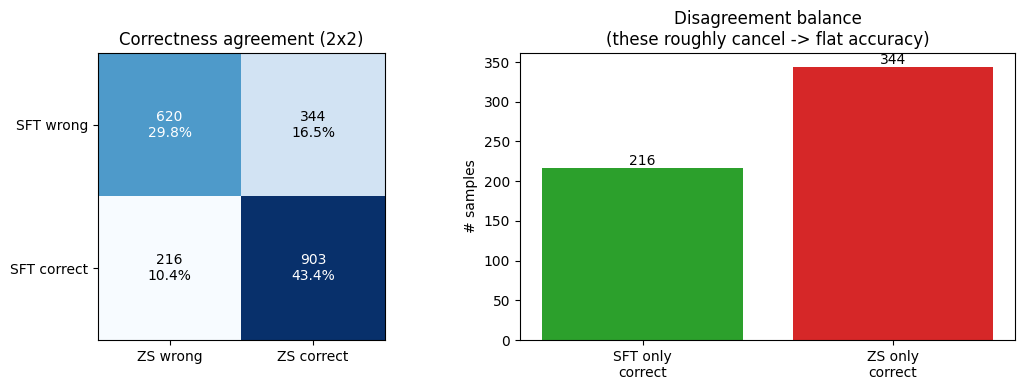

In [7]:
# Visualize the confusion as a heatmap + the disagreement balance.
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

cm = np.array([[both_wrong, zs_only], [sft_only, both_correct]])
im = ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["ZS wrong", "ZS correct"])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["SFT wrong", "SFT correct"])
for (i, j), v in np.ndenumerate(cm):
    ax[0].text(j, i, f"{v}\n{v/n:.1%}", ha="center", va="center",
               color="white" if v > cm.max()/2 else "black")
ax[0].set_title("Correctness agreement (2x2)")

ax[1].bar(["SFT only\ncorrect", "ZS only\ncorrect"], [sft_only, zs_only],
          color=["tab:green", "tab:red"])
ax[1].set_title("Disagreement balance\n(these roughly cancel -> flat accuracy)")
ax[1].set_ylabel("# samples")
for i, v in enumerate([sft_only, zs_only]):
    ax[1].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()


**Read this:** a high both-correct + both-wrong fraction means the two runs mostly agree; SFT only flips a small set, and if SFT-only ≈ ZS-only those flips cancel and accuracy stays flat. That is the difference between *SFT did nothing* and *SFT churned predictions without net benefit*.

## 3. How much did the generated answers actually change?

Accuracy can be flat for two reasons: (a) the model produces nearly identical answers, or (b) answers change but quality doesn't. We separate the two. We compare the **final `<answer>` text** (the judge only sees the candidate answer, so the `<think>` block doesn't affect the score).

In [8]:
def extract_answer(text):
    """Pull the <answer>...</answer> span; fall back to the whole string."""
    if not isinstance(text, str):
        return ""
    m_ = re.search(r"<answer>(.*?)</answer>", text, flags=re.DOTALL | re.IGNORECASE)
    return (m_.group(1) if m_ else text).strip()

def has_grounded_format(text):
    """Does the generation use the trained <obj>...</obj> grounding markup?"""
    return bool(isinstance(text, str) and re.search(r"<obj>.*?</obj>", text, flags=re.DOTALL))

def mentions_red_bbox(text):
    return bool(isinstance(text, str) and re.search(r"red bound|red box|bounding box", text, re.IGNORECASE))

def norm(s):
    return re.sub(r"\s+", " ", s.strip().lower()).strip(" .")

m["ans_sft"] = m["generated_answer_sft"].map(extract_answer)
m["ans_zs"]  = m["generated_answer_zs"].map(extract_answer)
m["answer_identical"] = m["ans_sft"].map(norm) == m["ans_zs"].map(norm)

print(f"identical final answers (normalized): {m.answer_identical.mean():.1%}")
print(f"changed final answers              : {(~m.answer_identical).mean():.1%}")


identical final answers (normalized): 7.4%
changed final answers              : 92.6%


answers changed on 1929 samples

score_delta distribution among CHANGED answers:
score_delta
-3      13
-2     105
-1     427
 0    1015
 1     317
 2      46
 3       6
Name: count, dtype: int64

mean score_delta | changed answers: -0.129
mean score_delta | all samples    : -0.118


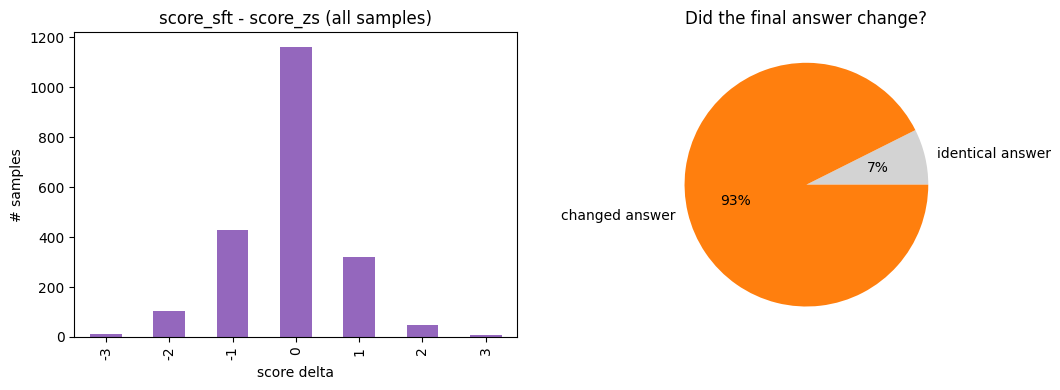

In [9]:
# Of the samples whose answer changed, what happened to the score?
changed = m[~m.answer_identical]
print(f"answers changed on {len(changed)} samples\n")
print("score_delta distribution among CHANGED answers:")
print(changed.score_delta.value_counts().sort_index())
print(f"\nmean score_delta | changed answers: {changed.score_delta.mean():+.3f}")
print(f"mean score_delta | all samples    : {m.score_delta.mean():+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
m.score_delta.value_counts().sort_index().plot.bar(ax=ax[0], color="tab:purple")
ax[0].set_title("score_sft - score_zs (all samples)")
ax[0].set_xlabel("score delta"); ax[0].set_ylabel("# samples")

ax[1].pie([m.answer_identical.sum(), (~m.answer_identical).sum()],
          labels=["identical answer", "changed answer"], autopct="%1.0f%%",
          colors=["lightgray", "tab:orange"])
ax[1].set_title("Did the final answer change?")
plt.tight_layout(); plt.show()


**Read this:** if most answers are *identical*, SFT changed the reasoning style (the `<think>` markup) but not the conclusion the judge sees — which would fully explain flat accuracy despite the CoT attending to the boxes. If answers changed a lot but `score_delta ≈ 0`, the changes are quality-neutral.

## 4. Does the grounded format actually show up, and does it help?

Sanity-check the premise: confirm the SFT run uses the `<obj>` markup far more than zeroshot, and check whether using it correlates with being correct. If the format appears but correctness is independent of it, the grounding is cosmetic.

In [10]:
m["fmt_sft"] = m["generated_answer_sft"].map(has_grounded_format)
m["fmt_zs"]  = m["generated_answer_zs"].map(has_grounded_format)
m["redmention_sft"] = m["generated_answer_sft"].map(mentions_red_bbox)
m["redmention_zs"]  = m["generated_answer_zs"].map(mentions_red_bbox)

print("uses <obj> grounding markup:")
print(f"   SFT: {m.fmt_sft.mean():.1%}   ZS: {m.fmt_zs.mean():.1%}")
print("mentions red bounding box:")
print(f"   SFT: {m.redmention_sft.mean():.1%}   ZS: {m.redmention_zs.mean():.1%}")

print("\nSFT accuracy split by whether it used the grounded format:")
print(m.groupby("fmt_sft").correct_sft.agg(["mean", "count"]).rename(columns={"mean": "accuracy"}))


uses <obj> grounding markup:
   SFT: 42.0%   ZS: 0.0%
mentions red bounding box:
   SFT: 72.2%   ZS: 5.0%

SFT accuracy split by whether it used the grounded format:
         accuracy  count
fmt_sft                 
False    0.536424   1208
True     0.538286    875


## 5. Per-domain breakdown

Maybe SFT helps in some domains and hurts in others, washing out in the mean. Compare per-domain accuracy and the net flip count.

                  n  acc_zs  acc_sft  sft_only  zs_only  acc_delta
domain                                                            
Entertainments  511   0.487    0.452        62       80     -0.035
Life            479   0.647    0.601        53       75     -0.046
Indoor          433   0.628    0.577        45       67     -0.051
Sports          192   0.677    0.568        13       34     -0.109
Animals         174   0.638    0.552        14       29     -0.086
Vehicle         101   0.653    0.455         7       27     -0.198
Nature           85   0.682    0.600         8       15     -0.082
Shows            75   0.573    0.560        11       12     -0.013
Tutorial         33   0.242    0.182         3        5     -0.061


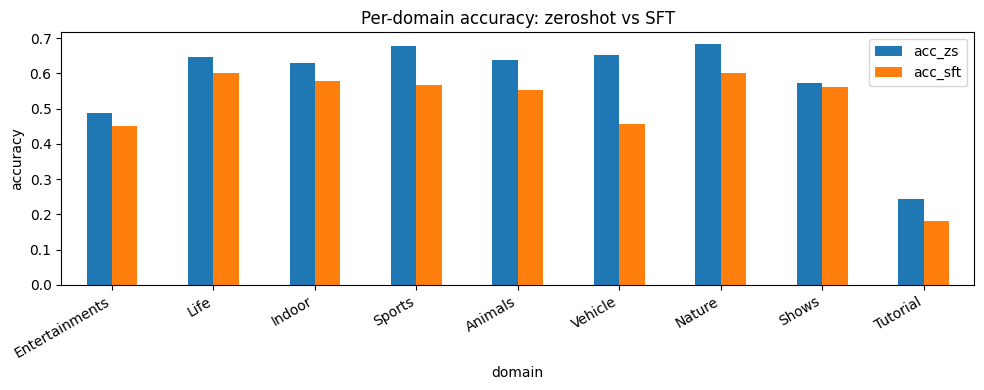

In [11]:
m["_sft_only"] = m.correct_sft & ~m.correct_zs
m["_zs_only"]  = ~m.correct_sft & m.correct_zs
dom = m.groupby("domain").agg(
    n=("qid", "size"),
    acc_zs=("correct_zs", "mean"),
    acc_sft=("correct_sft", "mean"),
    sft_only=("_sft_only", "sum"),
    zs_only=("_zs_only", "sum"),
)
dom["acc_delta"] = dom.acc_sft - dom.acc_zs
dom = dom.sort_values("n", ascending=False)
print(dom.round(3))

ax = dom[["acc_zs", "acc_sft"]].plot.bar(figsize=(10, 4))
ax.set_title("Per-domain accuracy: zeroshot vs SFT")
ax.set_ylabel("accuracy"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()


## 6. Inspect the disagreement cases (text side by side)

These are the samples that actually flipped. Read them to judge *why* SFT changed the answer and whether the red box helped or distracted.

In [12]:
def show_cases(df, n=8, cols_full=False):
    """Print qid / question / GT / both answers + scores for a slice of cases.

    Also shows the GT temporal/spatial sub-questions joined from the V-STaR
    annotation file: the grounding (`Q`) question is what the model answered,
    but the same sample carries a temporal question (with its GT time window)
    and two spatial-question phrasings.
    """
    for _, r in df.head(n).iterrows():
        print("=" * 100)
        print(f"qid: {r.qid}   domain: {r.domain}   score SFT={r.score_sft} ZS={r.score_zs}")
        print(f"Q  : {r.question}")
        print(f"GT : {r.gt_answer}")
        print(f"T-Q: {r.temporal_question}  (GT window {r.timestamps}s)")
        print(f"S-Q: {r.spatial_question}")
        print(f"S-Q2: {r.spatial_question_2}")
        print(f"\n[SFT correct={r.correct_sft}] answer: {r.ans_sft}")
        if cols_full:
            print(f"   full SFT gen: {r.generated_answer_sft}")
        print(f"[ZS  correct={r.correct_zs}] answer: {r.ans_zs}")
    print("=" * 100)

sft_fixed  = m[(m.correct_sft) & (~m.correct_zs)]   # SFT got it right, ZS wrong
sft_broke  = m[(~m.correct_sft) & (m.correct_zs)]   # SFT broke a previously-right answer
print(f"SFT-only-correct: {len(sft_fixed)} cases | ZS-only-correct: {len(sft_broke)} cases")


SFT-only-correct: 216 cases | ZS-only-correct: 344 cases


In [13]:
print("########## CASES SFT FIXED (SFT correct, ZS wrong) ##########\n")
show_cases(sft_fixed, n=6, cols_full=True)

########## CASES SFT FIXED (SFT correct, ZS wrong) ##########

qid: 6297019062_0   domain: Nature   score SFT=3 ZS=1
Q  : who is above the round and pink baby seat?
GT : there is a baby above the round and pink baby seat.
T-Q: When is the moment 'there is a baby above the round and pink baby seat.'?  (GT window [52.1, 58.3]s)
S-Q: Where is the baby above the round and pink baby seat between 52.1s~58.3s?
S-Q2: Where is the baby above the round and pink baby seat?

[SFT correct=True] answer: The baby above the round and pink baby seat is wearing a yellow costume with a matching yellow hat.
   full SFT gen: <think>
There are several babies in the video, each sitting in a baby seat. The image displays a baby in a pink and yellow costume sitting in a green baby seat, another baby in a pink outfit sitting in a purple baby seat, and a baby in a red and black outfit sitting in a pink baby seat. The pink baby seat has a round and pink design on top, and above it, there is a baby in a yellow out

In [16]:
print("########## CASES SFT BROKE (ZS correct, SFT wrong) ##########\n")
show_cases(sft_broke, n=40, cols_full=True)

########## CASES SFT BROKE (ZS correct, SFT wrong) ##########

qid: 7771650716_0   domain: Animals   score SFT=1 ZS=2
Q  : what walks in front of a man in white?
GT : a dog with a rope walks in front of a man in white.
T-Q: When is the moment 'a dog with a rope walks in front of a man in white' occurring?  (GT window [0.0, 13.0]s)
S-Q: Where is the dog with a rope during the event of walking in front of a man in white between 0s and 13s?
S-Q2: Where is the dog with a rope during the event of walking in front of a man in white?

[SFT correct=False] answer: the dog
   full SFT gen: <think><obj>dog</obj>at<t>11</t>s is highlighted by a red bounding box and is walking in front of a man in white. The man in white is holding the dog on a leash.</think>
<answer>the dog</answer>
[ZS  correct=True] answer: A dog walks in front of a man in white.
qid: 9293415110_1   domain: Shows   score SFT=1 ZS=2
Q  : who is in front of the guitar at theshow?
GT : there is an adult in a black dress in front of

In [15]:
# Hardest shared failures: both wrong with score 0/1. If the red box is on the
# right object here, the bottleneck is reasoning, not grounding.
both_wrong_hard = m[(~m.correct_sft) & (~m.correct_zs)].sort_values(["score_sft", "score_zs"])
print(f"{len(both_wrong_hard)} samples both runs got wrong. Showing the lowest-scoring:\n")
show_cases(both_wrong_hard, n=6, cols_full=True)


620 samples both runs got wrong. Showing the lowest-scoring:

qid: 4757890069_0   domain: Vehicle   score SFT=0 ZS=0
Q  : who is inside the red bus outdoors?
GT : an adult is inside a red bus outdoors.
T-Q: When is the moment 'an adult is inside a red bus outdoors.'?  (GT window [16.0, 23.0]s)
S-Q: Where is the adult inside the red bus outdoors between 16.0s~23.0s?
S-Q2: Where is the adult inside the red bus outdoors?

[SFT correct=False] answer: The people inside the red fire truck are the ones inside the red vehicle outdoors. There is no red bus in the video.
   full SFT gen: <think>
There are no red bounding boxes that clearly indicate a red bus in the video. The bounding boxes highlight a fire truck and a red fire truck. The fire truck is outdoors and there are people inside it. The bounding box around the fire truck shows two people inside, one in the driver's seat and the other in the passenger seat. There is no indication of a red bus in the video.
</think>
<answer>
The people i

## 7. Visualize the annotated video for a chosen `qid`

Render the V-STaR video with the **same red bbox the model saw**, by sampling frames exactly as the inference pipeline does (`process_vision_info`, 1 fps, cap 768) and overlaying the stored masks as bounding boxes. Use this to check whether the red box is on the object the question is about — i.e. whether bad answers are a *grounding* problem or a *reasoning* problem.

> **Run this section in the inference conda/venv** (the one used by `scripts/benchmark/vstar/qwen_infer_vg.py`). It needs `qwen_vl_utils`, `decord`/`torchvision`, and `ffmpeg`, and reads the source mp4 — the base analysis env (sections 1-6, just pandas/numpy/matplotlib) does not have these. It's isolated here so the rest of the notebook runs anywhere.

In [13]:
from qwen_vl_utils import process_vision_info
from src.utils.annotation_utils import load_mask_annotations, annotate_frames
from src.utils.notebook_utils import show_video

VIDEO_LOAD_CONFIG = {  # mirrors the inference / annotation pipeline
    "type": "video",
    "total_pixels": 16056320,
    "min_pixels": 12544,
    "fps": 1.0,
}

def render_annotated_video(qid, fps=4, width=520):
    """Decode the source video the same way inference did and overlay the red bbox.

    Frame i of the sampled tensor lines up with mask key i (both come from the
    identical process_vision_info sampling), so annotate_frames aligns exactly.
    """
    vid = qid.rsplit("_", 1)[0]
    vid_path = os.path.join(VIDEO_ROOT, f"{vid}.mp4")
    ann_path = os.path.join(ANN_ROOT, "masks", f"{qid}.json")
    if not os.path.exists(ann_path):
        print(f"no annotation file for {qid} (was it in the missing list?)"); return
    if not os.path.exists(vid_path):
        print(f"no video at {vid_path}"); return

    messages = [{"content": [{**VIDEO_LOAD_CONFIG, "video": vid_path}]}]
    _, video_inputs = process_vision_info(messages)
    frames = video_inputs[0]  # (T, 3, H, W) tensor

    record = load_mask_annotations(ann_path)
    annotated = annotate_frames(frames, record["masks_np"], annotation_type="bbox", thickness=3)
    annotated = np.stack(annotated)  # (T, H, W, 3) uint8

    row = m[m.qid == qid]
    if len(row):
        r = row.iloc[0]
        print(f"qid {qid} | domain {r.domain}")
        print(f"Q  : {r.question}")
        print(f"GT : {r.gt_answer}")
        print(f"T-Q: {r.temporal_question}  (GT window {r.timestamps}s)")
        print(f"S-Q: {r.spatial_question}")
        print(f"SFT (score {r.score_sft}): {r.ans_sft}")
        print(f"ZS  (score {r.score_zs}): {r.ans_zs}")
        print(f"\n[SFT full CoT]\n{r.generated_answer_sft}")
    print(f"sampled {len(annotated)} frames @ {annotated.shape[2]}x{annotated.shape[1]}")
    return show_video(frames=annotated, fps=fps, width=width)


In [17]:
# Pick a case to inspect. A "SFT broke it" case is usually the most informative:
# if the box is correctly on the object yet SFT still answered wrong, the problem
# is reasoning/over-reliance on the box, not grounding.
example_qid = "3830567237_0"
render_annotated_video(example_qid, fps=1)


qid 3830567237_0 | domain Life
Q  : who is behind the other adult in the yard?
GT : An adult is behind another adult in a yard.
T-Q: When is the moment 'an adult is behind another adult in a yard'?  (GT window [14.7, 20.2]s)
S-Q: Where is the adult behind another adult in the yard between 14.7s~20.2s?
SFT (score 0): the donkey
ZS  (score 2): The person behind the other adult in the yard is a man wearing a white shirt.

[SFT full CoT]
<think><obj>the donkey</obj>at<t>0</t>s is behind the other adult in the yard. The donkey is standing beside the adult and is the only animal visible in the yard. The other adult is standing to the left of the donkey, and there is another adult visible in the background, but they are not behind the donkey. The donkey is positioned in front of the other adult in the yard. </think>
<answer>the donkey</answer>
sampled 22 frames @ 644x476


'/tmp/_preview.mp4'

In [22]:
# Show the raw (un-annotated) video for a qid, sampled at 1 fps like inference.
def show_qid_video(qid, fps=4, width=520):
    """Decode the source video at 1 fps (process_vision_info) and display it."""
    vid = qid.rsplit("_", 1)[0]
    vid_path = os.path.join(VIDEO_ROOT, f"{vid}.mp4")
    if not os.path.exists(vid_path):
        print(f"no video at {vid_path}"); return

    messages = [{"content": [{**VIDEO_LOAD_CONFIG, "video": vid_path}]}]
    _, video_inputs = process_vision_info(messages)
    frames = video_inputs[0]  # (T, 3, H, W) tensor

    print(f"qid {qid} | sampled {len(frames)} frames @ {frames.shape[3]}x{frames.shape[2]}")
    return show_video(frames=frames, fps=fps, width=width)

show_qid_video("4757890069_0")


qid 4757890069_0 | sampled 38 frames @ 644x476


'/tmp/_preview.mp4'